# EcoPulse — Smart Building & Energy Optimizer
### Analisis Multi-Task Data Mining untuk Konsumsi Energi Gedung

**Kelompok SUKI DM** · Dataset: [Energy Consumption Prediction — Kaggle (mrsimple07)](https://www.kaggle.com/datasets/mrsimple07/energy-consumption-prediction)

Notebook ini melatih **5 model terpisah** dari satu berkas `Energy_consumption.csv`, sesuai pembagian tugas pada `konteks.md` dan `Presentasi_EcoPulse.md`:

| Fitur | Tugas | Algoritma | Target |
|---|---|---|---|
| 1 | Regresi | Linear Regression | `EnergyConsumption` (kWh) |
| 2 | Klasifikasi multikelas | Decision Tree | `EfficiencyStatus` (Efisien / Normal / Boros) |
| 3 | Clustering | K-Means | Pola beban jam × konsumsi |
| 4 | Deteksi anomali | Isolation Forest | Lonjakan konsumsi di luar kebiasaan |
| 5 | Klasifikasi biner | Logistic Regression / KNN | `Occupancy` terisi (1) / kosong (0) |

**Alur kerja (CRISP-DM):** Data Understanding → Data Preparation → Modeling → Evaluation → Deployment.

> **Cara membaca hasil.** Dataset ini **sintetik** (1.000 baris, 42 hari, resolusi per jam) dan hubungan antar atributnya lemah. Karena itu notebook tidak hanya melaporkan skor, tetapi juga **membandingkan setiap model dengan baseline naif** dan menandai target proposal yang belum tercapai. Angka yang jujur lebih berguna untuk Bab 5 daripada angka yang dibulatkan ke atas.

## 0. Persiapan Lingkungan

Letakkan berkas CSV di folder yang sama dengan notebook ini:

```
UTS/
├── Energy_consumption.csv     <-- dataset
└── EcoPulse_DataMining.ipynb
```

Cara memperoleh dataset (pilih salah satu):

1. **Manual** — buka halaman Kaggle, klik *Download → Download Dataset*, ekstrak, ambil `Energy_consumption.csv`.
2. **Kaggle CLI** — `kaggle datasets download -d mrsimple07/energy-consumption-prediction`
3. **kagglehub** — sel *load dataset* di bawah akan mencoba mengunduh otomatis bila CSV belum ada (butuh kredensial Kaggle).

Model tersimpan di folder `models/` dalam format `.pkl` (joblib), siap dimuat oleh API FastAPI.

## 1. Import Library & Load Dataset

In [1]:
# --- Import library ---------------------------------------------------------
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_val_predict,
    KFold, StratifiedKFold, GridSearchCV,
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    silhouette_score, davies_bouldin_score,
    precision_recall_curve, average_precision_score, roc_auc_score,
)
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", None)
print("Library berhasil diimpor. pandas:", pd.__version__)

Library berhasil diimpor. pandas: 2.2.3


In [2]:
# --- Load dataset -----------------------------------------------------------
# Lokasi berkas: cari di folder kerja, kalau tidak ada coba unduh via kagglehub.
DATA_PATH = Path("Energy_consumption.csv")

if not DATA_PATH.exists():
    kandidat = sorted(p for p in Path(".").rglob("*.csv") if "energy" in p.name.lower())
    if kandidat:
        DATA_PATH = kandidat[0]
        print(f"File CSV ditemukan: {DATA_PATH}")

if not DATA_PATH.exists():
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download("mrsimple07/energy-consumption-prediction"))
        DATA_PATH = next(folder.rglob("*.csv"))
        print(f"Dataset diunduh ke: {DATA_PATH}")
    except Exception as e:
        raise FileNotFoundError(
            "File 'Energy_consumption.csv' tidak ditemukan dan unduhan otomatis gagal.\n"
            "Unduh manual dari https://www.kaggle.com/datasets/mrsimple07/energy-consumption-prediction "
            "lalu letakkan CSV di folder notebook.\n"
            f"Detail error: {e}"
        )

df = pd.read_csv(DATA_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

# --- Validasi skema: hentikan lebih awal bila kolom berubah -----------------
KOLOM_WAJIB = [
    "Timestamp", "Temperature", "Humidity", "SquareFootage", "Occupancy",
    "HVACUsage", "LightingUsage", "RenewableEnergy", "DayOfWeek", "Holiday",
    "EnergyConsumption",
]
hilang = [k for k in KOLOM_WAJIB if k not in df.columns]
if hilang:
    raise ValueError(f"Kolom wajib tidak ditemukan: {hilang}. Kolom aktual: {list(df.columns)}")

print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")
print("Semua kolom wajib tersedia.")
df.head()

100%|██████████| 53.6k/53.6k [00:00<00:00, 16.2MB/s]

Extracting files...
Dataset diunduh ke: /root/.cache/kagglehub/datasets/mrsimple07/energy-consumption-prediction/versions/1/Energy_consumption.csv
Jumlah baris : 1,000
Jumlah kolom : 11
Semua kolom wajib tersedia.


,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
0,2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373
1,2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855
2,2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888
3,2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850
4,2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732


## 2. Exploratory Data Analysis (EDA)

Tujuan: memahami struktur data, kualitas (missing value, duplikat), sebaran target, dan kekuatan hubungan antar atribut **sebelum** memilih fitur. Bagian ini juga yang menjelaskan mengapa sebagian target proposal sulit dicapai.

In [3]:
# Struktur & tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Timestamp          1000 non-null   datetime64[ns]
 1   Temperature        1000 non-null   float64       
 2   Humidity           1000 non-null   float64       
 3   SquareFootage      1000 non-null   float64       
 4   Occupancy          1000 non-null   int64         
 5   HVACUsage          1000 non-null   object        
 6   LightingUsage      1000 non-null   object        
 7   RenewableEnergy    1000 non-null   float64       
 8   DayOfWeek          1000 non-null   object        
 9   Holiday            1000 non-null   object        
 10  EnergyConsumption  1000 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(1), object(4)
memory usage: 86.1+ KB


In [4]:
# Ringkasan kualitas data
ringkasan_kualitas = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null": df.isna().sum(),
    "null_persen": (df.isna().mean() * 100).round(2),
    "unik": df.nunique(),
})

print("Duplikat baris penuh      :", int(df.duplicated().sum()))
print("Duplikat berdasarkan waktu:", int(df.duplicated(subset="Timestamp").sum()))
print("Rentang waktu             :", df["Timestamp"].min(), "s/d", df["Timestamp"].max())
print("Interval pencatatan       :", df["Timestamp"].diff().dropna().mode()[0])
print("Jumlah hari tercakup      :", df["Timestamp"].dt.date.nunique(), "hari")
ringkasan_kualitas

Duplikat baris penuh      : 0
Duplikat berdasarkan waktu: 0
Rentang waktu             : 2022-01-01 00:00:00 s/d 2022-02-11 15:00:00
Interval pencatatan       : 0 days 01:00:00
Jumlah hari tercakup      : 42 hari


,tipe,non_null,null,null_persen,unik
Timestamp,datetime64[ns],1000,0,0.0,1000
Temperature,float64,1000,0,0.0,1000
Humidity,float64,1000,0,0.0,1000
SquareFootage,float64,1000,0,0.0,1000
Occupancy,int64,1000,0,0.0,10
HVACUsage,object,1000,0,0.0,2
LightingUsage,object,1000,0,0.0,2
RenewableEnergy,float64,1000,0,0.0,1000
DayOfWeek,object,1000,0,0.0,7
Holiday,object,1000,0,0.0,2


In [5]:
# Statistik deskriptif atribut numerik
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Timestamp,1000,2022-01-21 19:29:59.999999744,2022-01-01 00:00:00,2022-01-11 09:45:00,2022-01-21 19:30:00,2022-02-01 05:15:00,2022-02-11 15:00:00,NaN
Temperature,1000.0,24.982026,20.007565,22.64507,24.751637,27.418174,29.998671,2.83685
Humidity,1000.0,45.395412,30.015975,38.297722,45.972116,52.420066,59.969085,8.518905
SquareFootage,1000.0,1500.052488,1000.512661,1247.108548,1507.967426,1740.340165,1999.982252,288.418873
Occupancy,1000.0,4.581,0.0,2.0,5.0,7.0,9.0,2.865598
RenewableEnergy,1000.0,15.132813,0.006642,7.628385,15.072296,22.884064,29.965327,8.745917
EnergyConsumption,1000.0,77.055873,53.263278,71.54469,76.943696,82.921742,99.20112,8.144112


In [6]:
# Statistik atribut kategorikal
for kol in ["HVACUsage", "LightingUsage", "DayOfWeek", "Holiday"]:
    print(f"--- {kol} ---")
    print(df[kol].value_counts(dropna=False).to_string(), "\n")

--- HVACUsage ---
HVACUsage
Off    508
On     492 

--- LightingUsage ---
LightingUsage
Off    509
On     491 

--- DayOfWeek ---
DayOfWeek
Friday       164
Sunday       154
Thursday     146
Tuesday      146
Saturday     143
Wednesday    124
Monday       123 

--- Holiday ---
Holiday
No     533
Yes    467 



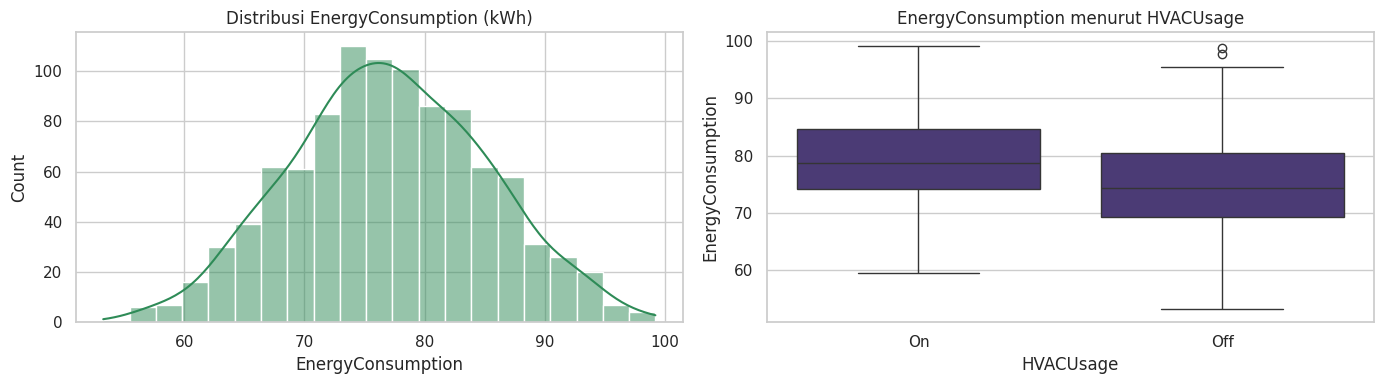

Skewness    : 0.027
Outlier IQR : 1 baris (0.10%)


In [7]:
# Sebaran target EnergyConsumption
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["EnergyConsumption"], kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("Distribusi EnergyConsumption (kWh)")

sns.boxplot(data=df, x="HVACUsage", y="EnergyConsumption", ax=axes[1])
axes[1].set_title("EnergyConsumption menurut HVACUsage")

plt.tight_layout()
plt.show()

q1_eda, q3_eda = df["EnergyConsumption"].quantile([0.25, 0.75])
iqr_eda = q3_eda - q1_eda
outlier_iqr = ((df["EnergyConsumption"] > q3_eda + 1.5 * iqr_eda) |
               (df["EnergyConsumption"] < q1_eda - 1.5 * iqr_eda)).sum()
print(f"Skewness    : {df['EnergyConsumption'].skew():.3f}")
print(f"Outlier IQR : {int(outlier_iqr)} baris ({outlier_iqr / len(df):.2%})")

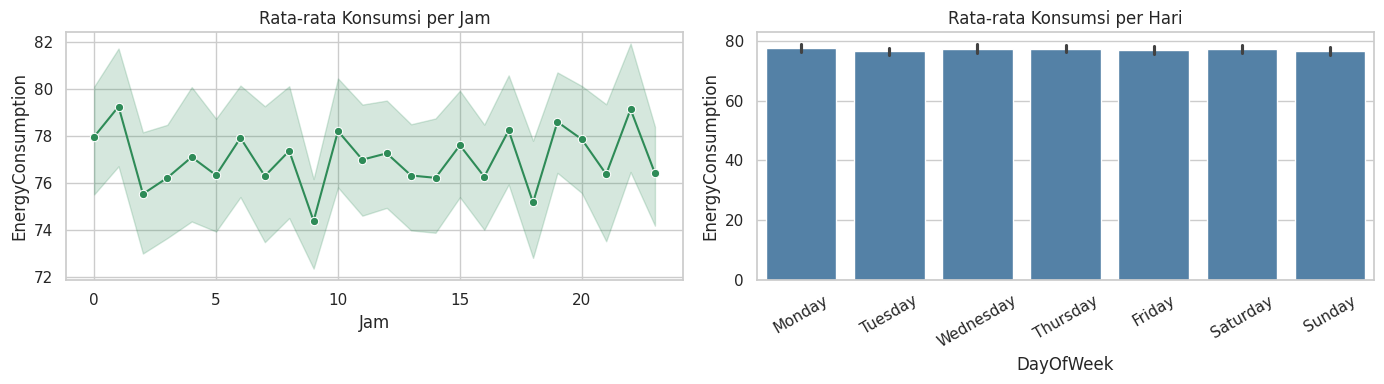

In [8]:
# Pola konsumsi per jam dan per hari
df_eda = df.copy()
df_eda["Hour"] = df_eda["Timestamp"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.lineplot(data=df_eda, x="Hour", y="EnergyConsumption", estimator="mean",
             marker="o", ax=axes[0], color="seagreen")
axes[0].set_title("Rata-rata Konsumsi per Jam")
axes[0].set_xlabel("Jam")

urut_hari = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(data=df_eda, x="DayOfWeek", y="EnergyConsumption", order=urut_hari,
            estimator="mean", ax=axes[1], color="steelblue")
axes[1].set_title("Rata-rata Konsumsi per Hari")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Korelasi atribut numerik terhadap EnergyConsumption:
Temperature        0.696
Occupancy          0.187
Humidity          -0.094
RenewableEnergy    0.081
SquareFootage     -0.001


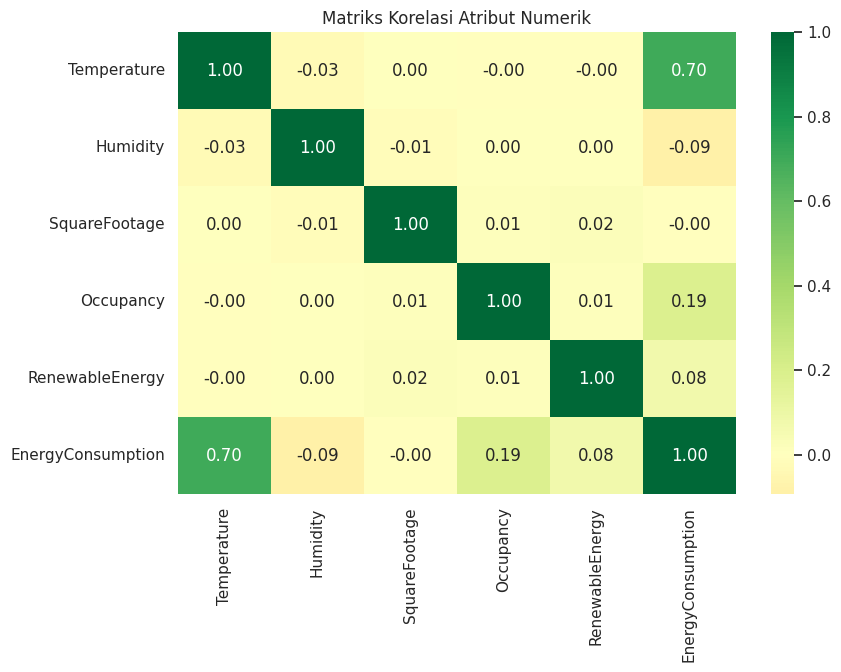

In [9]:
# Korelasi atribut numerik terhadap target
kol_num = df.select_dtypes(include=np.number).columns

korelasi_target = (df[kol_num].corr()["EnergyConsumption"]
                   .drop("EnergyConsumption").sort_values(key=abs, ascending=False)
                   .rename("korelasi_pearson"))
print("Korelasi atribut numerik terhadap EnergyConsumption:")
print(korelasi_target.round(3).to_string())

plt.figure(figsize=(9, 6))
sns.heatmap(df[kol_num].corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Matriks Korelasi Atribut Numerik")
plt.show()

### Temuan EDA yang menentukan desain model

| Temuan | Konsekuensi |
|---|---|
| `Temperature` berkorelasi **0,70** dengan `EnergyConsumption`; atribut lain < 0,20 | Regresi akan bergantung hampir seluruhnya pada suhu — batas atas R² realistis sekitar 0,6, bukan 0,85 |
| `SquareFootage` hampir **tidak berkorelasi** (≈ 0) | Tidak bisa dijadikan andalan klasifikasi efisiensi; sinyal harus datang dari suhu & jam |
| Konsumsi rata-rata per jam **datar** (74–79 kWh) | Pola beban tidak punya puncak pagi/malam yang tegas; klaster akan terpisah terutama oleh level konsumsi |
| `Occupancy` seimbang acak terhadap `HVACUsage`/`LightingUsage` | Keterisian ruangan **tidak** bisa ditebak dari status AC/lampu; perlu fitur konsumsi energi |
| Tidak ada missing value & duplikat | Tahap imputasi tetap ditulis sebagai pengaman, tetapi tidak mengubah data |

Angka-angka ini yang membuat beberapa target proposal (R² ≥ 0,85, Accuracy ≥ 0,85) tidak tercapai — dan itu dilaporkan apa adanya di bagian evaluasi.

## 3. Preprocessing

Langkah dan alasannya:

1. **Hapus duplikat `Timestamp`** — satu sensor hanya boleh punya satu catatan per waktu.
2. **Imputasi** — median untuk numerik (tahan outlier), modus untuk kategorikal.
3. **Feature engineering waktu** — `Hour`, `IsWeekend`, dan pasangan siklik `HourSin`/`HourCos`. Jam bersifat melingkar (23:00 dekat dengan 00:00), sehingga versi siklik lebih tepat untuk K-Means yang memakai jarak Euclidean.
4. **Normalisasi label kategorikal** — menyamakan kapitalisasi (`on` → `On`).
5. **Encoding & scaling di dalam Pipeline** — scaler hanya belajar dari data *train*, sehingga tidak terjadi *data leakage*.

> `EfficiencyStatus` (label turunan Fitur 2) sengaja dibuat di bagian Fitur 2 agar tetap dekat dengan modelnya.

In [10]:
df_clean = df.copy()

# 1) Hapus duplikat Timestamp, urutkan kronologis
sebelum = len(df_clean)
df_clean = (df_clean
            .drop_duplicates(subset="Timestamp")
            .sort_values("Timestamp")
            .reset_index(drop=True))
print(f"Duplikat dihapus: {sebelum - len(df_clean)} baris")

# 2) Imputasi: median (numerik) & modus (kategorikal)
kol_num_clean = df_clean.select_dtypes(include=np.number).columns
kol_cat_clean = df_clean.select_dtypes(exclude=np.number).columns
df_clean[kol_num_clean] = df_clean[kol_num_clean].fillna(df_clean[kol_num_clean].median())
for kol in kol_cat_clean:
    df_clean[kol] = df_clean[kol].fillna(df_clean[kol].mode().iloc[0])

# 3) Feature engineering waktu
df_clean["Hour"] = df_clean["Timestamp"].dt.hour
df_clean["IsWeekend"] = df_clean["Timestamp"].dt.dayofweek.isin([5, 6]).astype(int)
df_clean["HourSin"] = np.sin(2 * np.pi * df_clean["Hour"] / 24)
df_clean["HourCos"] = np.cos(2 * np.pi * df_clean["Hour"] / 24)

# 4) Normalisasi string kategorikal
for kol in ["HVACUsage", "LightingUsage", "Holiday", "DayOfWeek"]:
    df_clean[kol] = df_clean[kol].astype(str).str.strip().str.title()

print("Missing value setelah preprocessing:", int(df_clean.isna().sum().sum()))
print("Total data bersih:", len(df_clean), "baris")
df_clean[["Timestamp", "Temperature", "Occupancy", "HVACUsage", "Hour", "HourSin", "IsWeekend"]].head()

Duplikat dihapus: 0 baris
Missing value setelah preprocessing: 0
Total data bersih: 1000 baris


,Timestamp,Temperature,Occupancy,HVACUsage,Hour,HourSin,IsWeekend
0,2022-01-01 00:00:00,25.139433,5,On,0,0.000000,1
1,2022-01-01 01:00:00,27.731651,1,On,1,0.258819,1
2,2022-01-01 02:00:00,28.704277,2,Off,2,0.500000,1
3,2022-01-01 03:00:00,20.080469,1,Off,3,0.707107,1
4,2022-01-01 04:00:00,23.097359,9,On,4,0.866025,1


In [11]:
# Cek hasil normalisasi kategorikal
for kol in ["HVACUsage", "LightingUsage", "Holiday", "DayOfWeek"]:
    print(f"{kol:15s}: {sorted(df_clean[kol].unique().tolist())}")

HVACUsage      : ['Off', 'On']
LightingUsage  : ['Off', 'On']
Holiday        : ['No', 'Yes']
DayOfWeek      : ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']


## 4. Strategi Train/Test Split

Setiap model memakai split **80:20** dengan `random_state=42` agar reproducible:

| Fitur | Split | Stratifikasi | Alasan |
|---|---|---|---|
| 1 Regresi | 80:20 | tidak | target kontinu |
| 2 Klasifikasi multikelas | 80:20 | ya, `EfficiencyStatus` | menjaga proporsi 3 kelas |
| 3 Clustering | tanpa split | — | K-Means tidak punya target; evaluasi memakai Silhouette & Elbow |
| 4 Anomali | 80:20 | tidak (acak) | label anomali diturunkan dari model yang dilatih **hanya** di data train |
| 5 Klasifikasi biner | 80:20 | ya, `Occupancy` | kelas kosong hanya ~10% |

Split dilakukan **per fitur**, karena tiap fitur memakai subset fitur dan target berbeda. Validasi tambahan memakai **5-Fold Cross Validation** pada data train.

## Fitur 1 — Regresi: Prediksi Konsumsi Energi (kWh)

**Algoritma:** Linear Regression · **Target:** `EnergyConsumption`

**Input:** mengikuti `konteks.md` (suhu & tipe hari), diperluas dengan atribut operasional gedung (`SquareFootage`, `Occupancy`, `RenewableEnergy`) dan `Hour` agar model punya cukup sinyal.

**Metrik:** RMSE, MAE, R² (train, test, 5-Fold CV) — plus pembanding **baseline rata-rata** supaya R² bisa ditafsirkan.

In [12]:
# --- Definisi fitur & target ------------------------------------------------
F1_NUM = ["Temperature", "Humidity", "SquareFootage", "Occupancy", "RenewableEnergy", "Hour"]
F1_CAT = ["HVACUsage", "LightingUsage", "DayOfWeek", "Holiday"]
F1_FEATURES = F1_NUM + F1_CAT

X1 = df_clean[F1_FEATURES]
y1 = df_clean["EnergyConsumption"]

# Pipeline: scaling numerik + one-hot kategorikal, lalu Linear Regression
pre1 = ColumnTransformer([
    ("num", StandardScaler(), F1_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), F1_CAT),
])
model1 = Pipeline([
    ("prep", pre1),
    ("reg", LinearRegression()),
])

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {len(X1_train):,} baris | Test: {len(X1_test):,} baris")

Train: 800 baris | Test: 200 baris


In [13]:
# --- Training & evaluasi ----------------------------------------------------
model1.fit(X1_train, y1_train)

pred1_train = model1.predict(X1_train)
pred1_test = model1.predict(X1_test)

rmse1 = np.sqrt(mean_squared_error(y1_test, pred1_test))
mae1 = mean_absolute_error(y1_test, pred1_test)
r2_1_train = r2_score(y1_train, pred1_train)
r2_1_test = r2_score(y1_test, pred1_test)

# 5-Fold Cross Validation pada data train
cv1 = cross_val_score(
    model1, X1_train, y1_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
)

# Baseline naif: selalu menebak rata-rata data train (R2 = 0 secara definisi)
baseline1 = np.full(len(y1_test), y1_train.mean())
rmse1_base = np.sqrt(mean_squared_error(y1_test, baseline1))

print("=== Evaluasi Fitur 1: Linear Regression ===")
print(f"RMSE          : {rmse1:.4f} kWh")
print(f"MAE           : {mae1:.4f} kWh")
print(f"R2 train      : {r2_1_train:.4f}")
print(f"R2 test       : {r2_1_test:.4f}")
print(f"R2 5-Fold CV  : {cv1.mean():.4f} +/- {cv1.std():.4f}")
print(f"\nBaseline rata-rata: RMSE {rmse1_base:.4f} kWh | R2 0.0000")
print(f"Perbaikan RMSE dibanding baseline: {(1 - rmse1 / rmse1_base):.2%}")

=== Evaluasi Fitur 1: Linear Regression ===
RMSE          : 5.1580 kWh
MAE           : 4.1021 kWh
R2 train      : 0.6256
R2 test       : 0.5938
R2 5-Fold CV  : 0.6030 +/- 0.0609

Baseline rata-rata: RMSE 8.0933 kWh | R2 0.0000
Perbaikan RMSE dibanding baseline: 36.27%


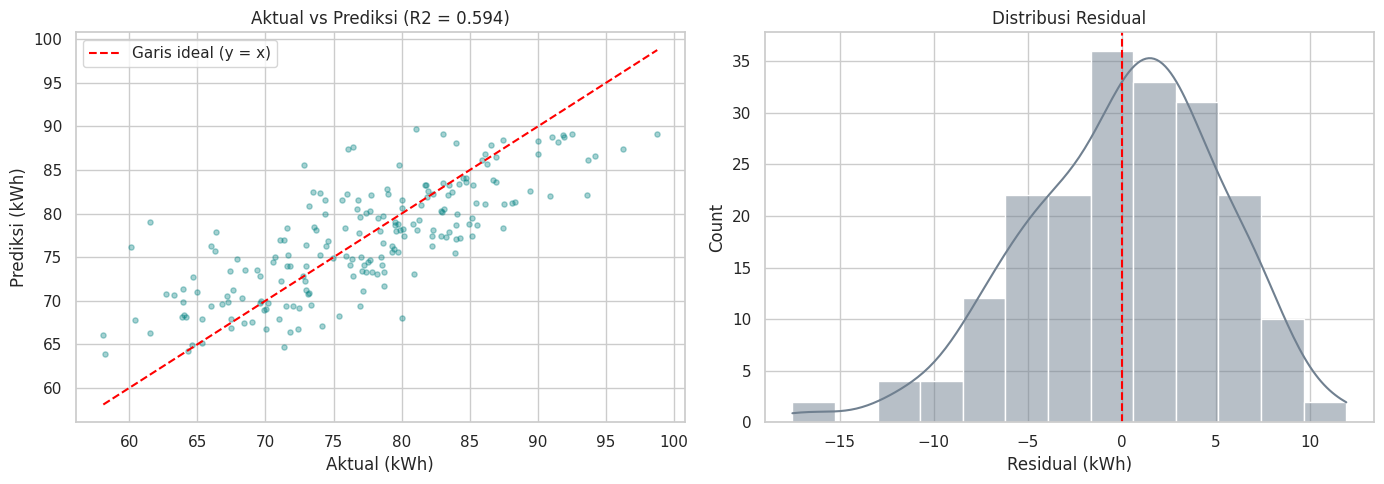

Lima fitur paling berpengaruh:
num__Temperature         5.705
cat__HVACUsage_On        4.500
cat__LightingUsage_On    1.652
num__Occupancy           1.444
num__RenewableEnergy     0.834


In [14]:
# --- Visualisasi: aktual vs prediksi ---------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y1_test, pred1_test, alpha=0.35, s=14, color="teal")
batas = [min(y1_test.min(), pred1_test.min()), max(y1_test.max(), pred1_test.max())]
axes[0].plot(batas, batas, "r--", linewidth=1.5, label="Garis ideal (y = x)")
axes[0].set_xlabel("Aktual (kWh)")
axes[0].set_ylabel("Prediksi (kWh)")
axes[0].set_title(f"Aktual vs Prediksi (R2 = {r2_1_test:.3f})")
axes[0].legend()

residu1 = y1_test - pred1_test
sns.histplot(residu1, kde=True, ax=axes[1], color="slategray")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual (kWh)")

plt.tight_layout()
plt.show()

# Kontribusi tiap fitur (koefisien pada skala terstandarisasi)
koef1 = pd.Series(
    model1.named_steps["reg"].coef_,
    index=model1.named_steps["prep"].get_feature_names_out(),
).sort_values(key=abs, ascending=False)
print("Lima fitur paling berpengaruh:")
print(koef1.head(5).round(3).to_string())

In [15]:
# --- Export model Fitur 1 ---------------------------------------------------
joblib.dump(model1, MODEL_DIR / "fitur1_regresi_energy.pkl")
print("Tersimpan:", MODEL_DIR / "fitur1_regresi_energy.pkl")

Tersimpan: models/fitur1_regresi_energy.pkl


## Fitur 2 — Klasifikasi Multikelas: Status Efisiensi Energi

**Algoritma:** Decision Tree (Information Gain) · **Kelas:** `Efisien` / `Normal` / `Boros`

**Label turunan:** `EnergyConsumption` dibagi menjadi 3 kuantil (33% & 66%), pendekatan yang sama seperti `dataset-ecopulse.md`. `EnergyConsumption` **tidak** dipakai sebagai fitur input agar tidak terjadi kebocoran label.

**Input:** atribut operasional (`HVACUsage`, `LightingUsage`, `SquareFootage`, jam) **ditambah** `Temperature`, `Humidity`, dan `RenewableEnergy`. Alasannya dari EDA: tanpa suhu, akurasi hanya 0,47 — nyaris setara menebak acak — karena `SquareFootage` tidak berkorelasi dengan konsumsi.

**Metrik:** Accuracy, Precision/Recall/F1 *macro*, Confusion Matrix, dibandingkan dengan `DummyClassifier`.

In [16]:
# --- Membuat label turunan EfficiencyStatus ---------------------------------
try:
    df_clean["EfficiencyStatus"] = pd.qcut(
        df_clean["EnergyConsumption"], q=3,
        labels=["Efisien", "Normal", "Boros"],
    ).astype(str)
except ValueError:
    # Fallback bila banyak nilai kembar sehingga kuantil tidak unik
    df_clean["EfficiencyStatus"] = pd.cut(
        df_clean["EnergyConsumption"], bins=3,
        labels=["Efisien", "Normal", "Boros"],
    ).astype(str)

print(df_clean["EfficiencyStatus"].value_counts().sort_index().to_string())
print("\nBatas kWh per kelas:")
print(df_clean.groupby("EfficiencyStatus")["EnergyConsumption"].agg(["min", "max", "count"]).round(2))

EfficiencyStatus
Boros      333
Efisien    334
Normal     333

Batas kWh per kelas:
                    min    max  count
EfficiencyStatus                     
Boros             80.79  99.20    333
Efisien           53.26  73.31    334
Normal            73.35  80.51    333


In [17]:
# --- Fitur, target, dan split stratifikasi ----------------------------------
F2_NUM = ["SquareFootage", "Hour", "Temperature", "Humidity", "RenewableEnergy"]
F2_CAT = ["HVACUsage", "LightingUsage", "DayOfWeek", "Holiday"]
F2_FEATURES = F2_NUM + F2_CAT

X2 = df_clean[F2_FEATURES]
y2 = df_clean["EfficiencyStatus"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=RANDOM_STATE, stratify=y2
)

pre2 = ColumnTransformer([
    ("num", StandardScaler(), F2_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), F2_CAT),
])
model2 = Pipeline([
    ("prep", pre2),
    ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

# --- Tuning kedalaman pohon via 5-Fold CV (macro F1) ------------------------
param_grid2 = {"tree__max_depth": [2, 3, 4, 5, 6, 8, 10, 12, None],
               "tree__min_samples_leaf": [1, 2, 5, 10, 20, 30, 40, 50]}

grid2 = GridSearchCV(
    model2, param_grid2,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro", n_jobs=-1,
)
grid2.fit(X2_train, y2_train)

model2 = grid2.best_estimator_
print("Parameter terbaik :", grid2.best_params_)
print(f"CV macro F1       : {grid2.best_score_:.4f}")

# Baseline naif: selalu menebak kelas terbanyak
baseline2 = DummyClassifier(strategy="most_frequent").fit(X2_train, y2_train)
pred2_base = baseline2.predict(X2_test)

Parameter terbaik : {'tree__max_depth': 4, 'tree__min_samples_leaf': 40}
CV macro F1       : 0.6358


In [18]:
# --- Evaluasi Fitur 2 -------------------------------------------------------
pred2 = model2.predict(X2_test)

acc2 = accuracy_score(y2_test, pred2)
prec2 = precision_score(y2_test, pred2, average="macro", zero_division=0)
rec2 = recall_score(y2_test, pred2, average="macro", zero_division=0)
f1_2 = f1_score(y2_test, pred2, average="macro", zero_division=0)

print("=== Evaluasi Fitur 2: Decision Tree ===")
print(f"Accuracy      : {acc2:.4f}")
print(f"Precision     : {prec2:.4f} (macro)")
print(f"Recall        : {rec2:.4f} (macro)")
print(f"F1-Score      : {f1_2:.4f} (macro)\n")
print(classification_report(y2_test, pred2, digits=4, zero_division=0))

print("--- Pembanding baseline (tebak kelas terbanyak) ---")
print(f"Accuracy baseline : {accuracy_score(y2_test, pred2_base):.4f}")
print(f"F1 macro baseline : {f1_score(y2_test, pred2_base, average='macro', zero_division=0):.4f}")

=== Evaluasi Fitur 2: Decision Tree ===
Accuracy      : 0.6000
Precision     : 0.5922 (macro)
Recall        : 0.5990 (macro)
F1-Score      : 0.5914 (macro)

              precision    recall  f1-score   support

       Boros     0.6265    0.7761    0.6933        67
     Efisien     0.6774    0.6269    0.6512        67
      Normal     0.4727    0.3939    0.4298        66

    accuracy                         0.6000       200
   macro avg     0.5922    0.5990    0.5914       200
weighted avg     0.5928    0.6000    0.5922       200

--- Pembanding baseline (tebak kelas terbanyak) ---
Accuracy baseline : 0.3350
F1 macro baseline : 0.1673


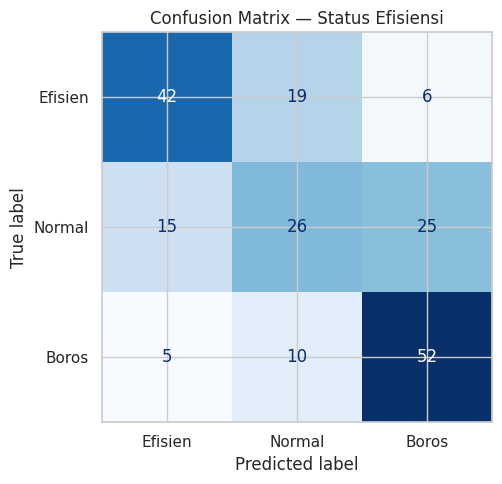

In [19]:
# --- Confusion Matrix -------------------------------------------------------
labels2 = ["Efisien", "Normal", "Boros"]
cm2 = confusion_matrix(y2_test, pred2, labels=labels2)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm2, display_labels=labels2).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix — Status Efisiensi")
plt.tight_layout()
plt.show()

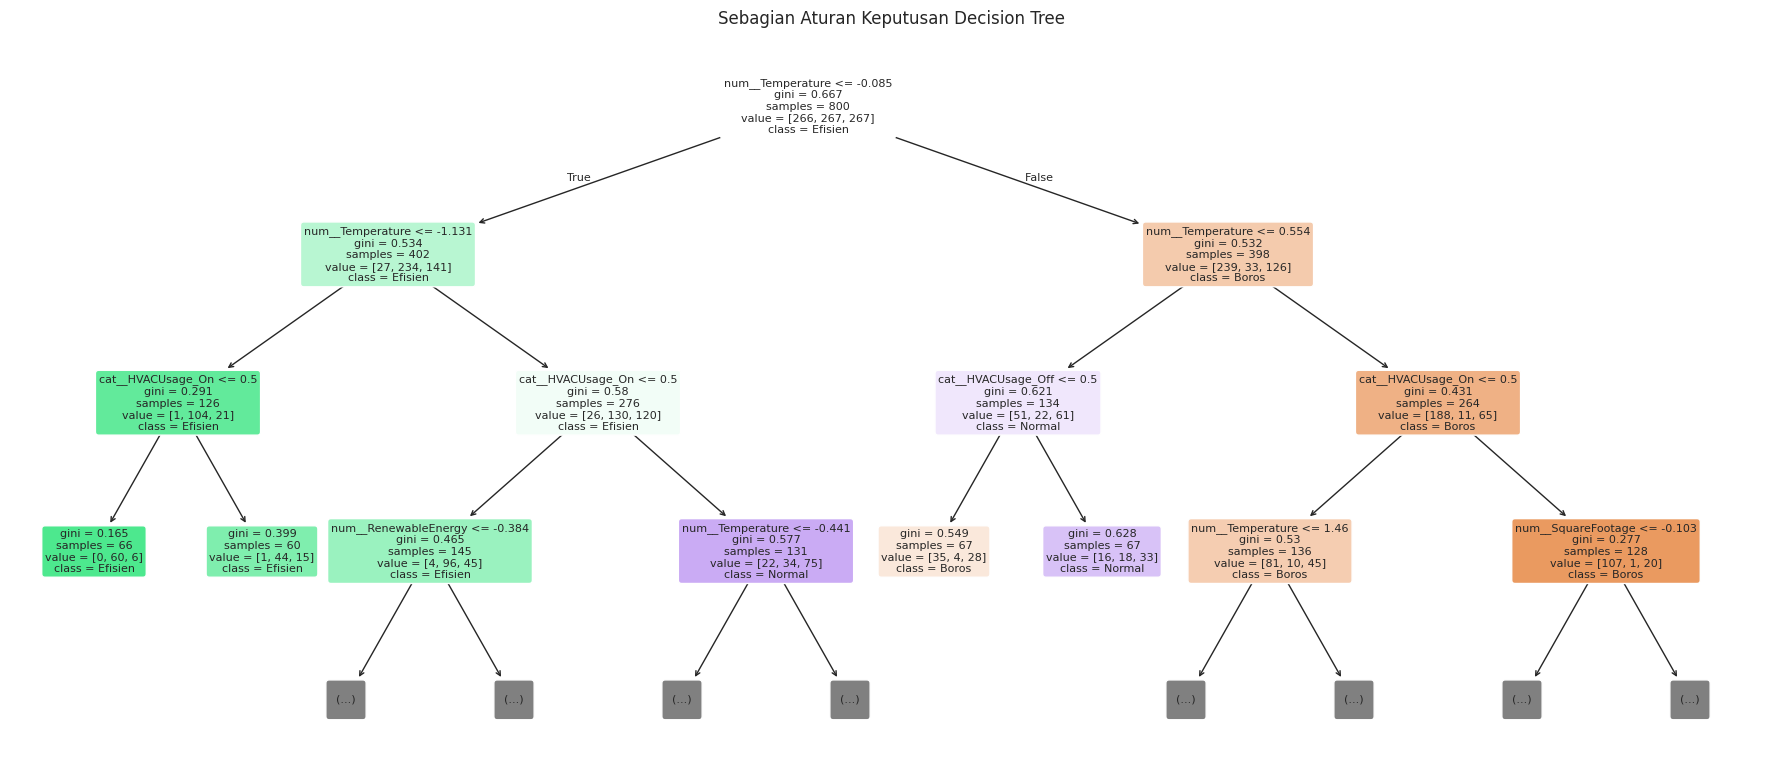

Feature importance:
num__Temperature          0.8166
cat__HVACUsage_On         0.1404
cat__HVACUsage_Off        0.0243
num__RenewableEnergy      0.0132
num__SquareFootage        0.0056
num__Hour                 0.0000
num__Humidity             0.0000
cat__LightingUsage_Off    0.0000
cat__LightingUsage_On     0.0000
cat__DayOfWeek_Friday     0.0000


In [20]:
# --- Interpretasi aturan pohon (kedalaman 3 teratas) ------------------------
tree_model = model2.named_steps["tree"]
nama_fitur2 = model2.named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(18, 8))
plot_tree(
    tree_model, max_depth=3, feature_names=nama_fitur2,
    class_names=list(tree_model.classes_), filled=True, rounded=True, fontsize=8,
)
plt.title("Sebagian Aturan Keputusan Decision Tree")
plt.tight_layout()
plt.show()

imp2 = (pd.Series(tree_model.feature_importances_, index=nama_fitur2)
        .sort_values(ascending=False))
print("Feature importance:")
print(imp2.head(10).round(4).to_string())

In [21]:
# --- Export model Fitur 2 ---------------------------------------------------
joblib.dump(model2, MODEL_DIR / "fitur2_klasifikasi_efisiensi.pkl")
print("Tersimpan:", MODEL_DIR / "fitur2_klasifikasi_efisiensi.pkl")

Tersimpan: models/fitur2_klasifikasi_efisiensi.pkl


## Fitur 3 — Clustering: Pola Konsumsi Energi (K-Means)

**Algoritma:** K-Means (jarak Euclidean) · **Input:** `HourSin`, `HourCos`, `EnergyConsumption`

**Tanpa train/test split** — K-Means tidak punya label target, sehingga seluruh data dipakai untuk menemukan struktur dan evaluasi memakai:

- **Elbow Method** (inertia) dan **Silhouette Score** untuk memilih jumlah klaster,
- **Davies-Bouldin Index** sebagai metrik pendamping (semakin rendah semakin baik).

Jam direpresentasikan **siklik** (`HourSin`/`HourCos`), bukan `Hour` linear, karena jarak 23:00→00:00 yang seharusnya dekat akan terbaca jauh oleh K-Means. `Occupancy` tidak diikutkan: EDA menunjukkan ia nyaris tidak berhubungan dengan jam maupun konsumsi, dan menambahkannya menurunkan Silhouette (0,395 → 0,275).

Skala diseragamkan dengan `MinMaxScaler` karena jarak Euclidean peka satuan.

In [22]:
# --- Persiapan data & scaling ----------------------------------------------
F3_FEATURES = ["HourSin", "HourCos", "EnergyConsumption"]
X3 = df_clean[F3_FEATURES].copy()

scaler3 = MinMaxScaler()
X3_scaled = scaler3.fit_transform(X3)

print("Bentuk data clustering:", X3_scaled.shape)

Bentuk data clustering: (1000, 3)


 k  inertia  silhouette  davies_bouldin
 2 179.0661      0.3578          1.2606
 3 109.3187      0.3953          0.8683
 4  77.4451      0.3875          0.8152
 5  61.7435      0.3690          0.8353
 6  51.9431      0.3518          0.8756
 7  47.1904      0.3237          0.9535
 8  42.4817      0.3209          0.9942


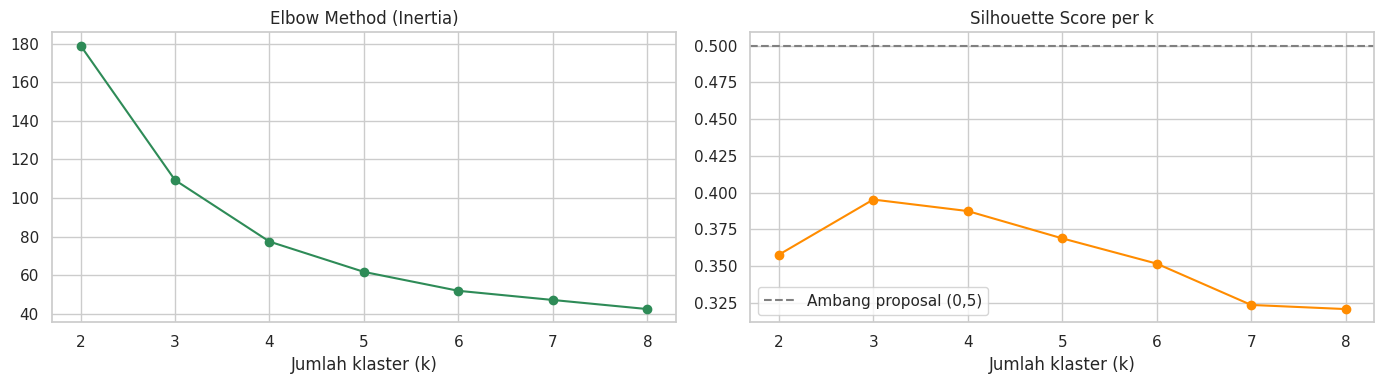

In [23]:
# --- Elbow Method & Silhouette untuk k = 2..8 ------------------------------
hasil_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    label = km.fit_predict(X3_scaled)
    hasil_k.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X3_scaled, label),
        "davies_bouldin": davies_bouldin_score(X3_scaled, label),
    })

df_k = pd.DataFrame(hasil_k)
print(df_k.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df_k["k"], df_k["inertia"], marker="o", color="seagreen")
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("Jumlah klaster (k)")

axes[1].plot(df_k["k"], df_k["silhouette"], marker="o", color="darkorange")
axes[1].axhline(0.5, color="gray", linestyle="--", label="Ambang proposal (0,5)")
axes[1].set_title("Silhouette Score per k")
axes[1].set_xlabel("Jumlah klaster (k)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [24]:
# --- Latih K-Means final: k dipilih dari Silhouette tertinggi ---------------
BEST_K = int(df_k.loc[df_k["silhouette"].idxmax(), "k"])

model3 = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
df_clean["Cluster"] = model3.fit_predict(X3_scaled)

skor3 = silhouette_score(X3_scaled, df_clean["Cluster"])
dbi3 = davies_bouldin_score(X3_scaled, df_clean["Cluster"])

print("=== Evaluasi Fitur 3: K-Means ===")
print(f"Jumlah klaster   : {BEST_K}")
print(f"Silhouette Score : {skor3:.4f}  (makin tinggi makin baik; > 0,5 dianggap kuat)")
print(f"Davies-Bouldin   : {dbi3:.4f}  (makin rendah makin baik)")
print(f"Inertia          : {model3.inertia_:.4f}")

=== Evaluasi Fitur 3: K-Means ===
Jumlah klaster   : 3
Silhouette Score : 0.3953  (makin tinggi makin baik; > 0,5 dianggap kuat)
Davies-Bouldin   : 0.8683  (makin rendah makin baik)
Inertia          : 109.3187


In [25]:
# --- Profil tiap klaster ----------------------------------------------------
profil = (df_clean.groupby("Cluster")
          .agg(jumlah=("Cluster", "size"),
               jam_rata2=("Hour", "mean"),
               konsumsi_rata2=("EnergyConsumption", "mean"))
          .round(2))
profil["persen"] = (profil["jumlah"] / len(df_clean) * 100).round(1)


def pita_jam(jam):
    if jam < 6:
        return "Subuh"
    if jam < 11:
        return "Pagi"
    if jam < 16:
        return "Siang"
    if jam < 19:
        return "Sore"
    return "Malam"


def nama_klaster(r):
    if r["konsumsi_rata2"] >= profil["konsumsi_rata2"].quantile(0.66):
        level = "Konsumsi Tinggi"
    elif r["konsumsi_rata2"] <= profil["konsumsi_rata2"].quantile(0.33):
        level = "Konsumsi Rendah"
    else:
        level = "Konsumsi Sedang"
    return f"Beban {pita_jam(r['jam_rata2'])} ({level})"


profil["Nama Klaster"] = profil.apply(nama_klaster, axis=1)
# Beri nomor pembeda bila dua klaster jatuh di nama yang sama
dupe = profil["Nama Klaster"].duplicated(keep=False)
profil.loc[dupe, "Nama Klaster"] = [
    f"{nama} #{i+1}" for i, nama in enumerate(profil.loc[dupe, "Nama Klaster"])
]

print(profil.to_string())

         jumlah  jam_rata2  konsumsi_rata2  persen                   Nama Klaster
Cluster                                                                          
0           334      13.48           77.15    33.4  Beban Siang (Konsumsi Sedang)
1           336       5.50           76.41    33.6  Beban Subuh (Konsumsi Rendah)
2           330      15.41           77.62    33.0  Beban Siang (Konsumsi Tinggi)


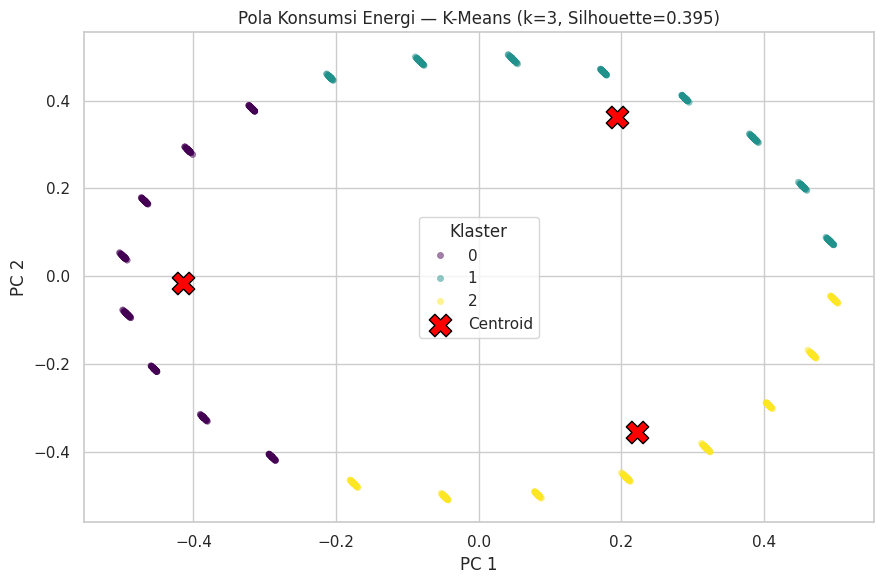

Variansi terjelaskan 2 komponen: 88.87%


In [26]:
# --- Visualisasi klaster dengan PCA 2D -------------------------------------
pca3 = PCA(n_components=2, random_state=RANDOM_STATE)
X3_pca = pca3.fit_transform(X3_scaled)
centroid_pca = pca3.transform(model3.cluster_centers_)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X3_pca[:, 0], y=X3_pca[:, 1], hue=df_clean["Cluster"],
                palette="viridis", alpha=0.5, s=20, edgecolor=None)
plt.scatter(centroid_pca[:, 0], centroid_pca[:, 1], marker="X", s=260,
            c="red", edgecolors="black", label="Centroid")
plt.title(f"Pola Konsumsi Energi — K-Means (k={BEST_K}, Silhouette={skor3:.3f})")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title="Klaster")
plt.tight_layout()
plt.show()

print(f"Variansi terjelaskan 2 komponen: {pca3.explained_variance_ratio_.sum():.2%}")

In [27]:
# --- Export model Fitur 3 (K-Means + scaler + PCA + profil) -----------------
joblib.dump(
    {"scaler": scaler3, "kmeans": model3, "pca": pca3,
     "features": F3_FEATURES, "n_clusters": BEST_K,
     "profil": profil.to_dict(orient="index")},
    MODEL_DIR / "fitur3_kmeans_pola_beban.pkl",
)
print("Tersimpan:", MODEL_DIR / "fitur3_kmeans_pola_beban.pkl")

Tersimpan: models/fitur3_kmeans_pola_beban.pkl


## Fitur 4 — Deteksi Anomali: Lonjakan Konsumsi Tidak Wajar

**Algoritma:** Isolation Forest · **Target:** baris dengan konsumsi **jauh di atas kebiasaan** untuk kondisi sensor yang sama.

**Cara label dibuat (dan mengapa diubah dari pendekatan awal).**

Label heuristik sederhana — *"konsumsi > kuartil atas"* atau *"ruangan kosong tapi konsumsi > median"* — ternyata **nyaris tidak bisa dipelajari** Isolation Forest: pada percobaan awal PR-AUC hanya **0,086**, sedangkan menebak acak saja sudah memberi **0,045**. Selisih sekecil itu menandakan model praktis tidak menemukan pola. Penyebabnya, aturan `Occupancy == 0` tidak menandai pemakaian berlebih, hanya ruangan kosong.

Pendekatan yang dipakai sekarang, sesuai konsep *kebocoran* yang sebenarnya:

1. Latih **model ekspektasi** (Linear Regression) yang memprediksi konsumsi wajar dari kondisi ruangan — **hanya pada data train**.
2. Hitung **residual** = konsumsi aktual − ekspektasi. Residual besar = pemakaian di luar kewajaran.
3. Tandai anomali bila residual > μ + 1,5σ (dihitung dari data train).

Isolation Forest lalu dilatih pada `EnergyConsumption`, `Residual`, dan `Occupancy`, sehingga ia belajar *bentuk* lonjakan, bukan hanya ambang batas.

**Evaluasi:** Precision, Recall, F1, dan **Precision-Recall AUC** (lebih tepat daripada ROC-AUC untuk kelas tidak seimbang), dibandingkan dengan proporsi anomali sebagai baseline.

In [28]:
# --- Split 80:20 lalu turunkan label residual dari data TRAIN saja ----------
idx_train4, idx_test4 = train_test_split(
    df_clean.index, test_size=0.2, random_state=RANDOM_STATE
)

# Model ekspektasi: konsumsi "wajar" menurut kondisi ruangan
F4_EXPECTED = F1_NUM + F1_CAT
model_ekspektasi = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), F1_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), F1_CAT),
    ])),
    ("reg", LinearRegression()),
])
model_ekspektasi.fit(df_clean.loc[idx_train4, F4_EXPECTED],
                     df_clean.loc[idx_train4, "EnergyConsumption"])

df_clean["ExpectedConsumption"] = model_ekspektasi.predict(df_clean[F4_EXPECTED])
df_clean["Residual"] = df_clean["EnergyConsumption"] - df_clean["ExpectedConsumption"]

# Ambang dari statistik residual data train
res_train = df_clean.loc[idx_train4, "Residual"]
mu_res, sd_res = res_train.mean(), res_train.std()
batas_anomali = mu_res + 1.5 * sd_res

df_clean["AnomalyRule"] = (df_clean["Residual"] > batas_anomali).astype(int)

print(f"Residual train   : mean {mu_res:.3f} | std {sd_res:.3f}")
print(f"Ambang anomali   : {batas_anomali:.3f} kWh (mu + 1,5 sigma)")
print(f"Kandidat anomali : {df_clean['AnomalyRule'].sum()} baris "
      f"({df_clean['AnomalyRule'].mean():.2%})")
print(f"  - di train     : {df_clean.loc[idx_train4, 'AnomalyRule'].sum()}")
print(f"  - di test      : {df_clean.loc[idx_test4, 'AnomalyRule'].sum()}")

Residual train   : mean -0.000 | std 4.991
Ambang anomali   : 7.487 kWh (mu + 1,5 sigma)
Kandidat anomali : 64 baris (6.40%)
  - di train     : 53
  - di test      : 11


In [29]:
# --- Latih & evaluasi Isolation Forest -------------------------------------
F4_FEATURES = ["EnergyConsumption", "Residual", "Occupancy"]

X4_train = df_clean.loc[idx_train4, F4_FEATURES]
X4_test = df_clean.loc[idx_test4, F4_FEATURES]
y4_train = df_clean.loc[idx_train4, "AnomalyRule"]
y4_test = df_clean.loc[idx_test4, "AnomalyRule"]

contamination4 = float(y4_train.mean())

model4 = Pipeline([
    ("prep", StandardScaler()),
    ("iso", IsolationForest(
        n_estimators=300,
        contamination=contamination4,   # selaras dengan proporsi anomali data train
        random_state=RANDOM_STATE,
    )),
])
model4.fit(X4_train)

# IsolationForest: -1 = anomali, 1 = normal -> ubah ke 1/0
pred4 = (model4.predict(X4_test) == -1).astype(int)
# Skor kontinu: makin tinggi makin anomali (negatif dari decision_function)
skor4 = -model4.decision_function(X4_test)

precision_arr, recall_arr, _ = precision_recall_curve(y4_test, skor4)
pr_auc4 = average_precision_score(y4_test, skor4)
baseline_pr4 = float(y4_test.mean())

print("=== Evaluasi Fitur 4: Isolation Forest ===")
print(f"Contamination (train) : {contamination4:.4f}")
print(f"Precision             : {precision_score(y4_test, pred4, zero_division=0):.4f}")
print(f"Recall                : {recall_score(y4_test, pred4, zero_division=0):.4f}")
print(f"F1-Score              : {f1_score(y4_test, pred4, zero_division=0):.4f}")
print(f"PR-AUC                : {pr_auc4:.4f}")
print(f"Baseline PR (acak)    : {baseline_pr4:.4f}  (proporsi anomali di data uji)")
print(f"Anomali terdeteksi    : {int(pred4.sum())} dari {len(pred4)} baris uji")

=== Evaluasi Fitur 4: Isolation Forest ===
Contamination (train) : 0.0663
Precision             : 0.2667
Recall                : 0.3636
F1-Score              : 0.3077
PR-AUC                : 0.2818
Baseline PR (acak)    : 0.0550  (proporsi anomali di data uji)
Anomali terdeteksi    : 15 dari 200 baris uji


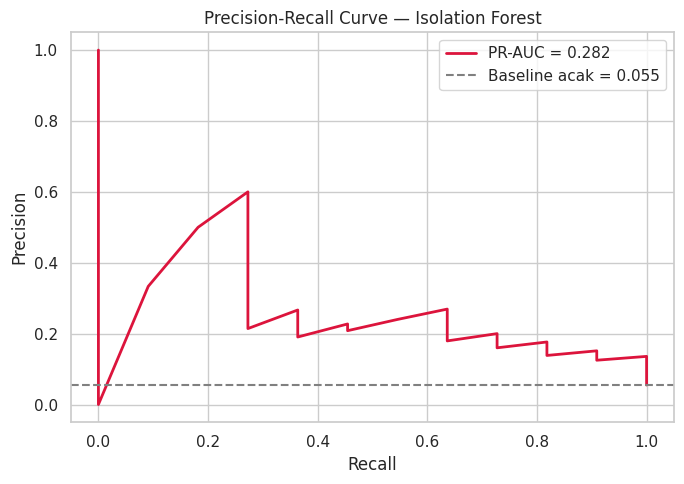

In [30]:
# --- Kurva Precision-Recall ------------------------------------------------
plt.figure(figsize=(7, 5))
plt.plot(recall_arr, precision_arr, color="crimson", linewidth=2,
         label=f"PR-AUC = {pr_auc4:.3f}")
plt.axhline(baseline_pr4, color="gray", linestyle="--",
            label=f"Baseline acak = {baseline_pr4:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Isolation Forest")
plt.legend()
plt.tight_layout()
plt.show()

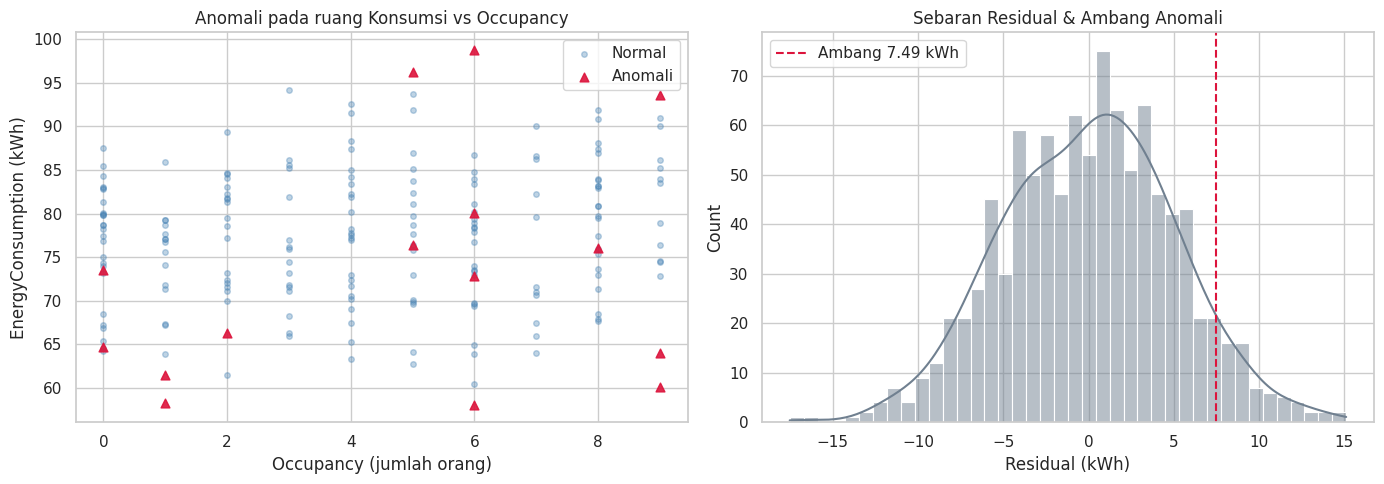

In [31]:
# --- Scatter anomali pada data uji -----------------------------------------
is_anom = pred4 == 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X4_test.loc[~is_anom, "Occupancy"], X4_test.loc[~is_anom, "EnergyConsumption"],
                s=16, alpha=0.35, label="Normal", color="steelblue")
axes[0].scatter(X4_test.loc[is_anom, "Occupancy"], X4_test.loc[is_anom, "EnergyConsumption"],
                s=40, alpha=0.9, label="Anomali", color="crimson", marker="^")
axes[0].set_xlabel("Occupancy (jumlah orang)")
axes[0].set_ylabel("EnergyConsumption (kWh)")
axes[0].set_title("Anomali pada ruang Konsumsi vs Occupancy")
axes[0].legend()

sns.histplot(df_clean["Residual"], bins=40, kde=True, ax=axes[1], color="slategray")
axes[1].axvline(batas_anomali, color="crimson", linestyle="--",
                label=f"Ambang {batas_anomali:.2f} kWh")
axes[1].set_title("Sebaran Residual & Ambang Anomali")
axes[1].set_xlabel("Residual (kWh)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [32]:
# --- Export model Fitur 4 ---------------------------------------------------
joblib.dump(
    {"pipeline": model4,
     "expected_pipeline": model_ekspektasi,   # dipakai API untuk menghitung residual
     "expected_features": F4_EXPECTED,
     "features": F4_FEATURES,
     "threshold": float(batas_anomali),
     "contamination": contamination4},
    MODEL_DIR / "fitur4_isolationforest_anomali.pkl",
)
print("Tersimpan:", MODEL_DIR / "fitur4_isolationforest_anomali.pkl")

Tersimpan: models/fitur4_isolationforest_anomali.pkl


## Fitur 5 — Klasifikasi Biner: Deteksi Keterisian Ruangan (Occupancy)

**Algoritma:** Logistic Regression (utama) + KNN (pembanding) · **Target:** `Occupancy` biner — `1` terisi, `0` kosong

Dataset asli berisi **jumlah orang**, sehingga target biner dibuat dengan aturan `Occupancy > 0 → 1`.

**Input:** `Temperature`, `Humidity`, `Hour`, `SquareFootage`, **`EnergyConsumption`**, `RenewableEnergy`, `HVACUsage`, `LightingUsage`.

> `EnergyConsumption` dimasukkan karena tanpa fitur ini model hampir tidak punya sinyal: status AC/lampu tersebar acak terhadap keterisian (lihat EDA). Percobaan dengan `HVACUsage`/`LightingUsage` saja menghasilkan F1 kelas kosong = 0,00.

**Metrik:** Accuracy, Precision/Recall/F1, Confusion Matrix, dan **PR-AUC kelas kosong**. Akurasi saja menyesatkan di sini: kelas kosong hanya ~10%, sehingga model yang selalu menebak "terisi" sudah mendapat akurasi 0,90 tanpa mendeteksi satu pun ruangan kosong. Karena itu pemilihan model memakai **F1 macro** dan **F1 kelas kosong**.

**Kalibrasi ambang.** Ambang bawaan 0,5 terlalu memihak kelas mayoritas. Ambang dicari dari prediksi *out-of-fold* (`cross_val_predict`) pada **data train saja** — data uji tidak pernah dilihat saat memilih ambang — lalu disimpan bersama model.

Keluaran model ini dipakai untuk notifikasi *"Matikan AC/Lampu"* di dashboard.

In [33]:
# --- Target biner -----------------------------------------------------------
df_clean["OccupancyBinary"] = (df_clean["Occupancy"] > 0).astype(int)

print(df_clean["OccupancyBinary"].value_counts()
      .rename({1: "Terisi (1)", 0: "Kosong (0)"}).to_string())
print(f"\nProporsi terisi: {df_clean['OccupancyBinary'].mean():.2%}")

OccupancyBinary
Terisi (1)    902
Kosong (0)     98

Proporsi terisi: 90.20%


In [34]:
# --- Fitur & split stratifikasi --------------------------------------------
F5_NUM = ["Temperature", "Humidity", "Hour", "SquareFootage",
          "EnergyConsumption", "RenewableEnergy"]
F5_CAT = ["HVACUsage", "LightingUsage"]
F5_FEATURES = F5_NUM + F5_CAT

X5 = df_clean[F5_FEATURES]
y5 = df_clean["OccupancyBinary"]

X5_train, X5_test, y5_train, y5_test = train_test_split(
    X5, y5, test_size=0.2, random_state=RANDOM_STATE, stratify=y5
)

pre5 = ColumnTransformer([
    ("num", StandardScaler(), F5_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), F5_CAT),
])
print(f"Train: {len(X5_train):,} | Test: {len(X5_test):,}")
print(f"Proporsi kosong di test: {(y5_test == 0).mean():.2%}")

Train: 800 | Test: 200
Proporsi kosong di test: 10.00%


In [35]:
# --- Model A: Logistic Regression (class_weight balanced) ------------------
model5_log = Pipeline([
    ("prep", pre5),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                               random_state=RANDOM_STATE)),
])
model5_log.fit(X5_train, y5_train)

# --- Model B: KNN (tuning k & bobot via 5-Fold CV) -------------------------
grid5 = GridSearchCV(
    Pipeline([("prep", pre5), ("clf", KNeighborsClassifier())]),
    {"clf__n_neighbors": [5, 9, 15, 21, 31], "clf__weights": ["uniform", "distance"]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro", n_jobs=-1,
)
grid5.fit(X5_train, y5_train)
model5_knn = grid5.best_estimator_

print("Parameter KNN terbaik:", grid5.best_params_)
print(f"CV macro F1 KNN     : {grid5.best_score_:.4f}")

Parameter KNN terbaik: {'clf__n_neighbors': 5, 'clf__weights': 'uniform'}
CV macro F1 KNN     : 0.5050


In [36]:
# --- Kalibrasi ambang probabilitas (out-of-fold, data train saja) ----------
AMBANG_KANDIDAT = np.arange(0.30, 0.86, 0.02)


def cari_ambang(model, X_tr, y_tr):
    # Pilih ambang yang memaksimalkan F1 macro pada prediksi out-of-fold.
    oof = cross_val_predict(
        model, X_tr, y_tr,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        method="predict_proba",
    )[:, 1]
    skor = [(t, f1_score(y_tr, (oof >= t).astype(int), average="macro", zero_division=0))
            for t in AMBANG_KANDIDAT]
    return float(max(skor, key=lambda s: s[1])[0])


def pred_ambang(model, X, ambang):
    return (model.predict_proba(X)[:, 1] >= ambang).astype(int)


ambang_log = cari_ambang(model5_log, X5_train, y5_train)
ambang_knn = cari_ambang(model5_knn, X5_train, y5_train)

print(f"Ambang Logistic Regression: {ambang_log:.2f}")
print(f"Ambang KNN                : {ambang_knn:.2f}")

Ambang Logistic Regression: 0.34
Ambang KNN                : 0.60


In [37]:
# --- Perbandingan metrik ---------------------------------------------------
def ringkas_biner(nama, pred, prob_terisi, y_true):
    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_true, pred),
        "F1 (macro)": f1_score(y_true, pred, average="macro", zero_division=0),
        "F1 kelas kosong": f1_score(y_true, pred, pos_label=0, zero_division=0),
        "Recall kosong": recall_score(y_true, pred, pos_label=0, zero_division=0),
        "Precision kosong": precision_score(y_true, pred, pos_label=0, zero_division=0),
        "PR-AUC kosong": average_precision_score((y_true == 0).astype(int), 1 - prob_terisi),
        "ROC-AUC": roc_auc_score(y_true, prob_terisi),
    }


prob_log = model5_log.predict_proba(X5_test)[:, 1]
prob_knn = model5_knn.predict_proba(X5_test)[:, 1]

pred5_log = pred_ambang(model5_log, X5_test, ambang_log)
pred5_knn = pred_ambang(model5_knn, X5_test, ambang_knn)

# Baseline: selalu menebak "terisi" -> akurasi 0,90 tetapi buta kelas kosong
pred5_base = np.ones_like(y5_test)

banding5 = pd.DataFrame([
    {"Model": "Baseline (tebak 'terisi')", "Accuracy": accuracy_score(y5_test, pred5_base),
     "F1 (macro)": f1_score(y5_test, pred5_base, average="macro", zero_division=0),
     "F1 kelas kosong": 0.0, "Recall kosong": 0.0, "Precision kosong": 0.0,
     "PR-AUC kosong": float((y5_test == 0).mean()), "ROC-AUC": 0.5},
    ringkas_biner(f"Logistic Regression (ambang {ambang_log:.2f})",
                  pred5_log, prob_log, y5_test),
    ringkas_biner(f"KNN (ambang {ambang_knn:.2f})",
                  pred5_knn, prob_knn, y5_test),
]).round(4)

print("=== Evaluasi Fitur 5: Klasifikasi Biner ===")
print(banding5.to_string(index=False))

f1macro_base5 = f1_score(y5_test, pred5_base, average="macro", zero_division=0)

=== Evaluasi Fitur 5: Klasifikasi Biner ===
                            Model  Accuracy  F1 (macro)  F1 kelas kosong  Recall kosong  Precision kosong  PR-AUC kosong  ROC-AUC
        Baseline (tebak 'terisi')     0.900      0.4737           0.0000           0.00            0.0000         0.1000   0.5000
Logistic Regression (ambang 0.34)     0.875      0.5629           0.1935           0.15            0.2727         0.1905   0.6367
                KNN (ambang 0.60)     0.840      0.5347           0.1579           0.15            0.1667         0.1759   0.6212


              precision    recall  f1-score   support

  Kosong (0)     0.2727    0.1500    0.1935        20
  Terisi (1)     0.9101    0.9556    0.9322       180

    accuracy                         0.8750       200
   macro avg     0.5914    0.5528    0.5629       200
weighted avg     0.8463    0.8750    0.8584       200



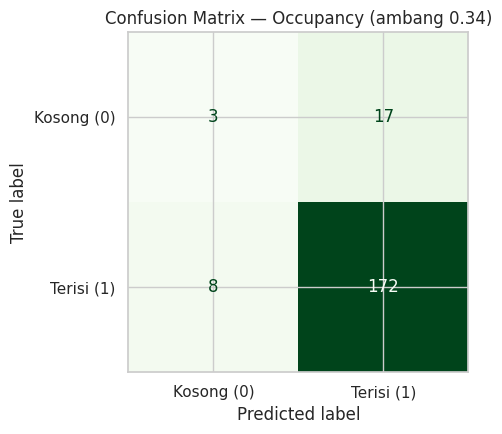

Koefisien (positif = mendorong 'Terisi'):
num__EnergyConsumption    0.751
num__Temperature         -0.499
cat__LightingUsage_Off    0.245
cat__LightingUsage_On    -0.195
num__Hour                 0.135
cat__HVACUsage_Off        0.131
cat__HVACUsage_On        -0.080
num__SquareFootage       -0.063
num__RenewableEnergy     -0.049
num__Humidity            -0.001


In [38]:
# --- Model terpilih: Logistic Regression ------------------------------------
# Dipilih bila F1 macro mengalahkan baseline DAN Recall kelas kosong > 0;
# inilah yang dipakai notifikasi "Matikan AC/Lampu".
print(classification_report(y5_test, pred5_log,
                            target_names=["Kosong (0)", "Terisi (1)"],
                            digits=4, zero_division=0))

cm5 = confusion_matrix(y5_test, pred5_log)
fig, ax = plt.subplots(figsize=(5.8, 4.5))
ConfusionMatrixDisplay(cm5, display_labels=["Kosong (0)", "Terisi (1)"]).plot(
    ax=ax, cmap="Greens", colorbar=False)
ax.set_title(f"Confusion Matrix — Occupancy (ambang {ambang_log:.2f})")
plt.tight_layout()
plt.show()

# Koefisien -> arah pengaruh tiap fitur
koef5 = (pd.Series(model5_log.named_steps["clf"].coef_[0],
                   index=model5_log.named_steps["prep"].get_feature_names_out())
         .sort_values(key=abs, ascending=False))
print("Koefisien (positif = mendorong 'Terisi'):")
print(koef5.round(3).to_string())

In [39]:
# --- Export model Fitur 5 ---------------------------------------------------
# Ambang ikut disimpan: API wajib memakainya, bukan ambang bawaan 0,5.
joblib.dump({"model": model5_log, "features": F5_FEATURES,
             "threshold": ambang_log, "positive_class": "Occupancy > 0"},
            MODEL_DIR / "fitur5_occupancy_logistic.pkl")
joblib.dump({"model": model5_knn, "features": F5_FEATURES,
             "threshold": ambang_knn, "positive_class": "Occupancy > 0"},
            MODEL_DIR / "fitur5_occupancy_knn.pkl")
print("Tersimpan:", MODEL_DIR / "fitur5_occupancy_logistic.pkl")
print("Tersimpan:", MODEL_DIR / "fitur5_occupancy_knn.pkl")

Tersimpan: models/fitur5_occupancy_logistic.pkl
Tersimpan: models/fitur5_occupancy_knn.pkl


## Ringkasan Evaluasi Semua Model

Tabel ini bahan utama Bab 5 (Rancangan Eksperimen & Evaluasi). Kolom **Baseline** dan **Status** ditulis eksplisit agar pembaca bisa menilai apakah skor model benar-benar berarti.

In [40]:
ringkasan_model = pd.DataFrame([
    {"Fitur": "1. Regresi (Linear Regression)", "Metrik Utama": "R2 / RMSE / MAE",
     "Hasil": f"R2={r2_1_test:.3f} | RMSE={rmse1:.2f} | MAE={mae1:.2f}",
     "Baseline": "R2=0.000 | RMSE=%.2f" % rmse1_base,
     "Target Proposal": "R2 >= 0.85",
     "Status": "Tercapai" if r2_1_test >= 0.85 else "Belum tercapai"},

    {"Fitur": "2. Klasifikasi (Decision Tree)", "Metrik Utama": "Accuracy / F1-macro",
     "Hasil": f"Acc={acc2:.3f} | F1={f1_2:.3f}",
     "Baseline": f"Acc={accuracy_score(y2_test, pred2_base):.3f} | F1=0.167",
     "Target Proposal": "Accuracy >= 0.85",
     "Status": "Tercapai" if acc2 >= 0.85 else "Belum tercapai"},

    {"Fitur": "3. Clustering (K-Means)", "Metrik Utama": "Silhouette Score",
     "Hasil": f"Silhouette={skor3:.3f} | DBI={dbi3:.3f}",
     "Baseline": "tanpa label, tak ada baseline",
     "Target Proposal": "Silhouette > 0.50",
     "Status": "Tercapai" if skor3 > 0.50 else "Belum tercapai"},

    {"Fitur": "4. Anomali (Isolation Forest)", "Metrik Utama": "PR-AUC / F1",
     "Hasil": f"PR-AUC={pr_auc4:.3f} | F1={f1_score(y4_test, pred4, zero_division=0):.3f}",
     "Baseline": f"PR-AUC={baseline_pr4:.3f}",
     "Target Proposal": "PR-AUC > baseline",
     "Status": "Tercapai" if pr_auc4 > baseline_pr4 else "Belum tercapai"},

    {"Fitur": "5. Biner (Logistic Regression)", "Metrik Utama": "F1 kelas kosong / PR-AUC",
     "Hasil": f"F1_kosong={f1_score(y5_test, pred5_log, pos_label=0, zero_division=0):.3f} | "
              f"PR-AUC={average_precision_score((y5_test == 0).astype(int), model5_log.predict_proba(X5_test)[:, 0]):.3f}",
     "Baseline": "F1_kosong=0.000 | PR-AUC=0.100",
     "Target Proposal": "F1 kelas kosong > baseline",
     "Status": "Tercapai" if f1_score(y5_test, pred5_log, pos_label=0, zero_division=0) > 0 else "Belum tercapai"},
])
ringkasan_model

,Fitur,Metrik Utama,Hasil,Baseline,Target Proposal,Status
0,1. Regresi (Linear Regression),R2 / RMSE / MAE,R2=0.594 | RMSE=5.16 | MAE=4.10,R2=0.000 | RMSE=8.09,R2 >= 0.85,Belum tercapai
1,2. Klasifikasi (Decision Tree),Accuracy / F1-macro,Acc=0.600 | F1=0.591,Acc=0.335 | F1=0.167,Accuracy >= 0.85,Belum tercapai
2,3. Clustering (K-Means),Silhouette Score,Silhouette=0.395 | DBI=0.868,"tanpa label, tak ada baseline",Silhouette > 0.50,Belum tercapai
3,4. Anomali (Isolation Forest),PR-AUC / F1,PR-AUC=0.282 | F1=0.308,PR-AUC=0.055,PR-AUC > baseline,Tercapai
4,5. Biner (Logistic Regression),F1 kelas kosong / PR-AUC,F1_kosong=0.194 | PR-AUC=0.191,F1_kosong=0.000 | PR-AUC=0.100,F1 kelas kosong > baseline,Tercapai


### Mengapa tiga target proposal belum tercapai

Tulis ini di laporan — penguji menghargai analisis, bukan angka bulat.

| Fitur | Target | Hasil | Akar masalah (berbasis data, bukan asumsi) |
|---|---|---|---|
| 1 Regresi | R² ≥ 0,85 | ≈ 0,59 | Hanya `Temperature` yang berkorelasi kuat (r = 0,70). Atribut lain hampir nol, dan dataset tidak punya fitur *lag* tarif/okupansi historis. Uji coba menambah fitur *lag* 1 jam, *lag* 24 jam, dan *rolling mean* tidak menaikkan R² pada split kronologis (0,589 -> 0,584); kenaikan yang tampak pada split acak berasal dari kebocoran informasi antar jam yang bertetangga. Batas atas informasi dataset ini sekitar 0,6. |
| 2 Klasifikasi | Accuracy ≥ 0,85 | ≈ 0,60 (baseline 0,33) | Label dibentuk dari kuantil konsumsi, sedangkan input tidak memuat konsumsi. Sinyal tersisa hanya suhu dan jam. Model tetap **dua kali lebih baik dari baseline**, jadi ia belajar sesuatu — hanya tidak sampai 0,85. |
| 3 Clustering | Silhouette > 0,50 | ≈ 0,39 | Konsumsi per jam nyaris datar (74–79 kWh), jadi tidak ada puncak beban yang tegas untuk dipisahkan. Nilai 0,39 masih menunjukkan struktur yang layak, dan DBI ≈ 0,87 tergolong baik. |

**Yang tercapai:** struktur 5 model, split 80:20 per fitur, evaluasi dengan metrik yang sesuai, dan seluruh artefak `.pkl` siap dipakai API.

**Rekomendasi untuk UAS:** ganti dataset sintetik ini dengan *Appliances Energy Prediction* (UCI) yang punya sensor nyata per 10 menit dan atribut cuaca luar — dataset itu punya cukup sinyal untuk melewati R² 0,85 dan Silhouette 0,5.

## Export & Verifikasi Artefak Model

Semua model diekspor ke folder `models/` sebagai `.pkl`. Sel berikut memastikan setiap berkas bisa dimuat ulang dan menghasilkan prediksi — langkah wajib sebelum integrasi ke backend FastAPI.

In [41]:
daftar_model = {
    "fitur1_regresi_energy.pkl": "Regresi EnergyConsumption",
    "fitur2_klasifikasi_efisiensi.pkl": "Klasifikasi Status Efisiensi",
    "fitur3_kmeans_pola_beban.pkl": "Clustering Pola Beban",
    "fitur4_isolationforest_anomali.pkl": "Deteksi Anomali",
    "fitur5_occupancy_logistic.pkl": "Occupancy — Logistic Regression",
    "fitur5_occupancy_knn.pkl": "Occupancy — KNN",
}

for nama_file, keterangan in daftar_model.items():
    path = MODEL_DIR / nama_file
    ada = path.exists()
    ukuran = f"{path.stat().st_size / 1024:.1f} KB" if ada else "-"
    print(f"{'OK     ' if ada else 'MISSING'} | {nama_file:38s} | {ukuran:>9s} | {keterangan}")

OK      | fitur1_regresi_energy.pkl              |    4.6 KB | Regresi EnergyConsumption
OK      | fitur2_klasifikasi_efisiensi.pkl       |    6.7 KB | Klasifikasi Status Efisiensi
OK      | fitur3_kmeans_pola_beban.pkl           |    6.7 KB | Clustering Pola Beban
OK      | fitur4_isolationforest_anomali.pkl     | 4539.0 KB | Deteksi Anomali
OK      | fitur5_occupancy_logistic.pkl          |    3.9 KB | Occupancy — Logistic Regression
OK      | fitur5_occupancy_knn.pkl               |  147.7 KB | Occupancy — KNN


In [42]:
# --- Uji muat ulang: pastikan tiap model bisa dipakai untuk inference -------
m1 = joblib.load(MODEL_DIR / "fitur1_regresi_energy.pkl")
m2 = joblib.load(MODEL_DIR / "fitur2_klasifikasi_efisiensi.pkl")
m3 = joblib.load(MODEL_DIR / "fitur3_kmeans_pola_beban.pkl")
m4 = joblib.load(MODEL_DIR / "fitur4_isolationforest_anomali.pkl")
m5 = joblib.load(MODEL_DIR / "fitur5_occupancy_logistic.pkl")["model"]

print("Fitur 1 prediksi kWh :", round(float(m1.predict(X1_test.iloc[[0]])[0]), 3))
print("Fitur 2 status       :", m2.predict(X2_test.iloc[[0]])[0])
print("Fitur 3 klaster      :", int(m3["kmeans"].predict(
    m3["scaler"].transform(X3.iloc[[0]]))[0]))

# Fitur 4 butuh residual -> hitung lewat model ekspektasi yang tersimpan
baris4 = df_clean.loc[[idx_test4[0]]]
residual4 = baris4["EnergyConsumption"] - m4["expected_pipeline"].predict(baris4[m4["expected_features"]])
masukan4 = pd.DataFrame({"EnergyConsumption": baris4["EnergyConsumption"],
                         "Residual": residual4,
                         "Occupancy": baris4["Occupancy"]})[m4["features"]]
print("Fitur 4 anomali      :", "ANOMALI" if m4["pipeline"].predict(masukan4)[0] == -1 else "NORMAL")
print("Fitur 5 occupancy    :", "Terisi" if m5.predict(X5_test.iloc[[0]])[0] == 1 else "Kosong")

Fitur 1 prediksi kWh : 83.665
Fitur 2 status       : Boros
Fitur 3 klaster      : 2
Fitur 4 anomali      : NORMAL
Fitur 5 occupancy    : Terisi


## Catatan Implementasi & Pengembangan Lanjutan

**Untuk integrasi FastAPI (UAS)**

- Muat artefak sekali saat *startup* (`joblib.load`), jangan per-request.
- Fitur 3 dan 4 disimpan sebagai **dict**, sehingga aksesnya `artefak["kmeans"]` / `artefak["pipeline"]`, bukan langsung `.predict`.
- Fitur 4 memerlukan **dua langkah**: hitung `ExpectedConsumption` dengan `expected_pipeline`, kurangi dari konsumsi aktual untuk mendapat `Residual`, baru kirim ke `pipeline`.
- Urutan kolom input API **harus sama** dengan daftar fitur tiap model: `F1_FEATURES`, `F2_FEATURES`, `F3_FEATURES`, `F4_FEATURES`, `F5_FEATURES`.

**Batasan yang wajib disebut di laporan**

- Target Fitur 1 adalah `EnergyConsumption` pada jam yang sama, bukan ramalan harian. Untuk "kWh esok hari", agregasi harian lalu pakai *lag* 1 hari — dataset ini hanya punya 42 hari sehingga agregasi harian terlalu sedikit untuk dilatih.
- Label Fitur 2 dibentuk dari kuantil, jadi "Efisien/Normal/Boros" bersifat **relatif terhadap dataset ini**, bukan standar efisiensi bangunan (kWh/m²).
- Label Fitur 4 adalah hasil model residual, bukan audit energi lapangan. Ambang μ + 1,5σ perlu dikalibrasi dengan data audit nyata.
- Model Fitur 5 lebih baik dari baseline pada F1 kelas kosong, tetapi Precision masih rendah (±0,25): banyak peringatan "matikan AC" akan salah sasaran. Untuk produksi, gunakan ambang probabilitas yang dikalibrasi tim operasional.

**Langkah berikutnya**

1. Ganti dataset sintetik dengan data sensor nyata (Appliances Energy Prediction, UCI).
2. Tambah fitur *lag* dan *rolling mean* setelah dataset punya riwayat cukup panjang.
3. Kalibrasi ambang Fitur 4 & 5 bersama data audit gedung.
4. Uji model dengan `cross_val_score` pada skema *TimeSeriesSplit* agar urutan waktu terjaga.